# 1. The process model on CMIP6 land carbon feedbacks

The TCRE development code explains each Earth system model's carbon feedbacks by the processes it
represents, and estimates the real world as an ensemble with every process switched on (Marvel et al.
2026, sections 3.5 and 4.3). This notebook fits that model to the 13 CMIP6 models and asks how much the
ensemble moves each term away from its prior.

Everything here can be changed and rerun: the data are plain tables, the priors are a dictionary, and
the model is built and sampled in two calls. Sampling results are read from a cache written by
`scripts/precompute.py`. Set `REFIT = True` below to sample live instead (a few minutes per fit), for
example after changing a prior.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tcre_evidence import process_tests as pt          # the development code's process model, and sampling
from tcre_evidence.plotting import style, SERIES
from tcre_evidence.paths import DATA, RESULTS

style()
pd.set_option("display.precision", 2)
CACHE = RESULTS / "precomputed" / "cmip6"   # written by scripts/precompute.py
REFIT = False                               # True: sample live instead of reading the cache (minutes per fit)

## Data

One value per model of each land feedback (β_L in PgC/ppm, γ_L in PgC/K, both in the COU−BGC convention
of the development code's inputs), and a 0/1 flag for each process. `family` groups models that share
code.

In [2]:
values = pd.read_csv(DATA / "examples" / "cmip6_land_feedbacks.csv", index_col="model")
flags = pd.read_csv(DATA / "examples" / "cmip6_process_flags.csv", index_col="model").loc[values.index]
family = flags.pop("family")
PROCESSES = list(flags.columns)

values.round(3).join(flags).join(family)

,beta_land_coubgc,gamma_land_coubgc,gamma_land_tropics_coubgc,gamma_land_extratropics_coubgc,nitrogen,permafrost,fire,veg,family
model,,,,,,,,,
ACCESS-ESM1-5,0.70,-10.11,-14.37,4.26,1,0,0,0,UM-ACCESS
BCC-CSM2-MR,2.19,-91.40,-42.34,-49.06,0,0,0,0,BCC-CSM2-MR
CanESM5,1.44,-6.30,-25.13,18.83,0,0,0,0,CanESM5
CESM2,0.99,-13.73,-14.59,0.86,1,1,1,0,NCAR
CMCC-ESM2,0.40,-9.39,-2.70,-6.69,1,1,1,0,NCAR
CNRM-ESM2-1,1.38,-46.17,-32.82,-13.35,0,0,1,0,NEMO-IPSL
EC-Earth3-CC,0.87,-13.89,-12.19,-1.70,1,0,1,1,NEMO-IPSL
GFDL-ESM4,1.07,-44.40,-37.34,-7.07,0,0,1,1,GFDL-ESM4
IPSL-CM6A-LR,0.96,-7.40,-11.73,4.33,0,0,0,0,NEMO-IPSL


In [3]:
# the quantity to analyse; for land beta use the second line instead
Q, KIND, LABEL = "gamma_land_coubgc", "additive", "γ_L (PgC/K)"
# Q, KIND, LABEL = "beta_land_coubgc", "multiplicative", "β_L (PgC/ppm)"

## What the flags see

The process model learns each effect from the difference between models with and without the process.
Each panel splits the ensemble by one flag; bars are group means.

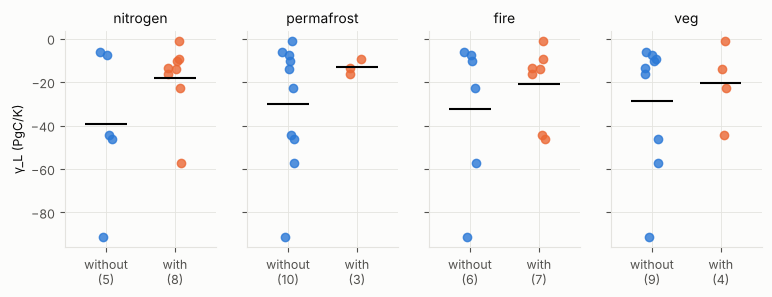

In [4]:
fig, axs = plt.subplots(1, len(PROCESSES), figsize=(9, 2.8), sharey=True)
jitter = np.random.default_rng(0).uniform(-0.1, 0.1, len(values))
for ax, p in zip(axs, PROCESSES):
    for x in (0, 1):
        m = flags[p] == x
        ax.plot(x + jitter[m.values], values.loc[m, Q], "o", color=SERIES[x], alpha=0.8)
        ax.hlines(values.loc[m, Q].mean(), x - 0.3, x + 0.3, color="k", lw=1.5)
    ax.set(title=p, xticks=[0, 1], xlim=(-0.6, 1.6),
           xticklabels=[f"without\n({(flags[p] == 0).sum()})", f"with\n({flags[p].sum()})"])
axs[0].set_ylabel(LABEL);

In [5]:
pd.DataFrame({p: {"models with": flags[p].sum(),
                   "mean with": values.loc[flags[p] == 1, Q].mean(),
                   "mean without": values.loc[flags[p] == 0, Q].mean(),
                   "families with": ", ".join(sorted(family[flags[p] == 1].unique()))}
              for p in PROCESSES}).T

,models with,mean with,mean without,families with
nitrogen,8,-18.11,-39.14,"MIROC-ES2L, MPI-ESM1-2-LR, NCAR, NEMO-IPSL, UM..."
permafrost,3,-13.21,-30.1,NCAR
fire,7,-20.75,-32.55,"GFDL-ESM4, MPI-ESM1-2-LR, NCAR, NEMO-IPSL"
veg,4,-20.61,-28.68,"GFDL-ESM4, MPI-ESM1-2-LR, NEMO-IPSL, UM-ACCESS"


## The model

For an additive quantity (γ_L) each model's value is

    y_m = U + Σ_p flag_mp (δ_p + e_mp) + b_common + b_m

and for a multiplicative one (β_L) the processes scale the baseline, U · exp(Σ_p flag_mp (log η_p + e_mp)).
U is the value with no processes, e_mp lets a process act differently in each model, b_common is an error
shared by all models (a share ρ of the structural variance) and b_m an error specific to model m.

The **real-world estimate** is U + Σ_p δ_p (or U · Π_p η_p): every listed process on, no errors.

The priors below are the development code's (`external/TCRE_Assessment/config/priors.py`). Edit them and
set `REFIT = True` to see the effect, for example
`priors["delta"]["permafrost"] = dict(dist="Normal", mu=0.0, sigma=10.0)`.

In [6]:
priors = pt.default_priors(KIND, PROCESSES)
priors

{'kind': 'additive',
 'baseline': {'dist': 'Normal', 'mu': 0.0, 'sigma': 100.0},
 'delta': {'nitrogen': {'dist': 'LogNormal',
   'mu': 2.302585092994046,
   'sigma': 1.0},
  'permafrost': {'dist': 'NegLogNormal',
   'mu': 3.4011973816621555,
   'sigma': 1.0},
  'fire': {'dist': 'Normal', 'mu': 0.0, 'sigma': 10.0},
  'veg': {'dist': 'Normal', 'mu': 0.0, 'sigma': 10.0}},
 'sigma_process_struct': {'nitrogen': 5.0,
  'permafrost': 100.0,
  'fire': 30.0,
  'veg': 50.0},
 'sigma_struct': {'sigma': 40.0},
 'likelihood_noise': 5.0}

In [7]:
model = pt.build(values[Q], flags, priors)   # the development code's own builder
print(model.str_repr())

           y_unscaled ~ Normal(0, 100)
       y_sigma_struct ~ HalfNormal(0, 40)
                y_rho ~ Beta(5, 5)
         y_bias_m_raw ~ Normal(0, 1)
    y_bias_common_raw ~ Normal(0, 1)
           y_nitrogen ~ LogNormal(2.3, 1)
negative_y_permafrost ~ LogNormal(3.4, 1)
               y_fire ~ Normal(0, 10)
                y_veg ~ Normal(0, 10)
            y_eps_add ~ Normal(0, <constant>)
       y_sigma_common ~ Deterministic(f(y_sigma_struct, y_rho))
            y_sigma_m ~ Deterministic(f(y_sigma_struct, y_rho))
             y_bias_m ~ Deterministic(f(y_bias_m_raw, y_sigma_struct, y_rho))
        y_bias_common ~ Deterministic(f(y_bias_common_raw, y_sigma_struct, y_rho))
         y_permafrost ~ Deterministic(f(negative_y_permafrost))
              y_delta ~ Deterministic(f(y_veg, y_fire, y_nitrogen, negative_y_permafrost))
                    y ~ Deterministic(f(y_unscaled, y_veg, y_fire, y_nitrogen, negative_y_permafrost))
               y_CMIP ~ Normal(f(y_bias_m_raw, y_bias_com

## Prior and posterior

The same terms before (grey) and after (blue) seeing the 13 models.

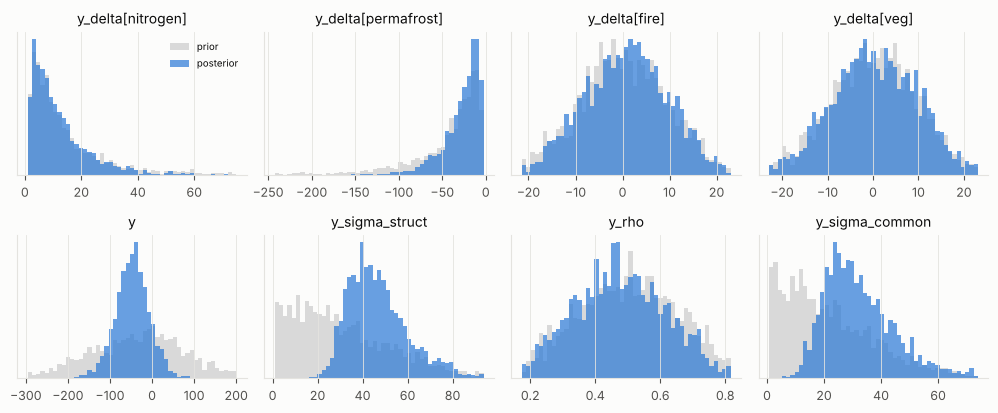

In [8]:
if REFIT:
    _, diag, draws = pt.prior_vs_posterior(values[Q], flags, priors, return_draws=True,
                                           sampler=dict(draws=500, tune=500, chains=2))
    print(diag)   # r-hat should be below 1.01
else:
    z = np.load(CACHE / Q / "draws.npz")
    draws = {k[:-6]: (z[k], z[k[:-6] + "|posterior"]) for k in z.files if k.endswith("|prior")}

fig, axs = plt.subplots(2, 4, figsize=(10, 4.2))
for ax, (term, (prior, post)) in zip(axs.ravel(), draws.items()):
    bins = np.linspace(*np.percentile(np.r_[prior, post], [1, 99]), 50)
    ax.hist(prior, bins, density=True, color="0.85", label="prior")
    ax.hist(post, bins, density=True, color=SERIES[0], alpha=0.7, label="posterior")
    ax.set(title=term, yticks=[])
axs[0, 0].legend(fontsize=7)
fig.tight_layout()

A compact summary: medians, and the ratio of the 90 % interval widths (posterior over prior; near 1
means the ensemble has not informed the term). Quantiles rather than standard deviations, because some
priors are skewed with long tails.

In [9]:
def compare(prior, post):
    a, b = np.percentile(prior, [5, 50, 95]), np.percentile(post, [5, 50, 95])
    return {"prior median": a[1], "posterior median": b[1], "posterior 5-95 %": f"{b[0]:.3g} to {b[2]:.3g}",
            "width ratio": (b[2] - b[0]) / (a[2] - a[0])}

pd.DataFrame({term: compare(*d) for term, d in draws.items()}).T

,prior median,posterior median,posterior 5-95 %,width ratio
y_delta[nitrogen],9.77,9.11,2 to 33,0.61
y_delta[permafrost],-29.83,-21.4,-71 to -4.9,0.45
y_delta[fire],0.07,0.96,-14.3 to 15.5,0.91
y_delta[veg],0.33,0.26,-15 to 15.8,0.95
y,-26.48,-45.86,-114 to 20.2,0.35
y_sigma_struct,26.1,44.78,29.2 to 74.3,0.62
y_rho,0.51,0.47,0.245 to 0.715,0.92
y_sigma_common,18.37,30.27,16 to 57.4,0.77


A narrower posterior is not proof that a term is learned. The data can rule out a prior's tail (as for
permafrost) without measuring the effect. Notebook 2 tests directly whether known effects can be
recovered from an ensemble like this one.

To repeat this for β_L, switch the `Q, KIND, LABEL` line above and rerun the notebook.